# 002 · 看见Larmor进动

保留官方初态(2|0⟩+|1⟩)/sqrt(5)。原文在third_party/qutip_tutorials/002_larmor-precession.md。

对H=f(t)σz，Bloch向量绕z轴转动，角度是2∫f(t)dt。先预测恒定、线性、周期场的相位，再看图。

In [1]:
from pathlib import Path
import sys
import numpy as np
import qutip as qt
import matplotlib.pyplot as plt
from IPython.display import display
root = Path.cwd()
if not (root / 'code').is_dir():
    root = root.parent
if not (root / 'code').is_dir():
    raise RuntimeError('请在项目根目录或notebooks目录运行')
sys.path.insert(0, str(root / 'code'))
print('当前解释器：', sys.executable)
options = dict(atol=1e-11, rtol=1e-9, method='dop853', store_states=True, normalize_output=False)


当前解释器： D:\Master.s-work\Software-needed-for-master.s-work\python\main\python.exe


In [2]:
psi=(2*qt.basis(2,0)+qt.basis(2,1)).unit()
times=np.linspace(0,10,501)
def linear(t):return 0.3*t
def periodic(t):return np.cos(0.5*t)
models=[('constant',qt.sigmaz(),2*times),
        ('linear',qt.QobjEvo([[qt.sigmaz(),linear]]),0.3*times**2),
        ('periodic',qt.QobjEvo([[qt.sigmaz(),periodic]]),4*np.sin(times/2))]
trajectories={}
for name,H,angle in models:
    result=qt.sesolve(H,psi,times,e_ops=[qt.sigmax(),qt.sigmay(),qt.sigmaz()],options=options)
    xyz=np.asarray(result.expect)
    reference=np.array([0.8*np.cos(angle),0.8*np.sin(angle),np.full(times.size,0.6)])
    np.testing.assert_allclose(xyz,reference,atol=1e-7,rtol=0)
    trajectories[name]=xyz
    print(name,'解析最大误差:',np.max(abs(xyz-reference)))


constant 解析最大误差: 2.1649348980190553e-15
linear 解析最大误差: 4.773959005888173e-15
periodic 解析最大误差: 8.43769498715119e-15


## 同时比较相位与Bloch轨迹
三个图的纵轴相同，便于比较；幺正演化的Bloch向量长度应保持1。

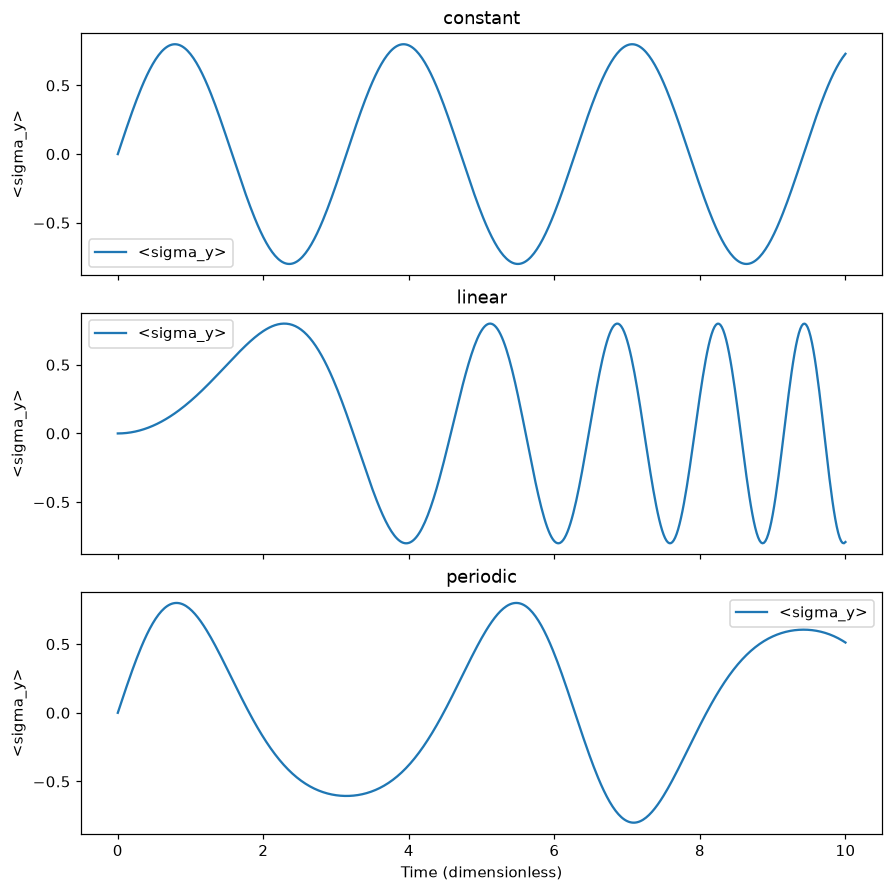

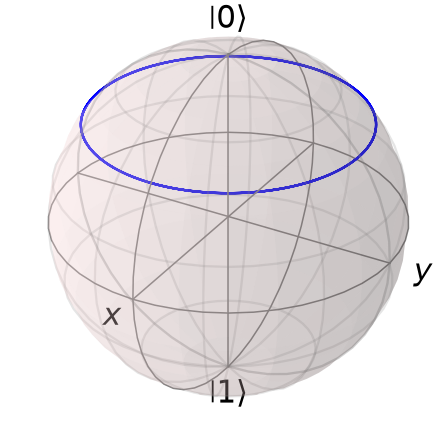

In [3]:
fig,axes=plt.subplots(3,1,figsize=(8,8),layout='constrained',sharex=True)
for ax,(name,xyz) in zip(axes,trajectories.items()):
    ax.plot(times,xyz[1],label='<sigma_y>')
    ax.set(ylabel='<sigma_y>',title=name)
    ax.legend()
axes[-1].set_xlabel('Time (dimensionless)')
display(fig);plt.close(fig)
fig=plt.figure(figsize=(6,5))
ax=fig.add_subplot(111,projection='3d')
sphere=qt.Bloch(fig=fig,axes=ax)
sphere.add_points(trajectories['constant'],meth='l');sphere.render()
display(fig);plt.close(fig)


## 自己改一处
把初态改成(|0⟩+i|1⟩)/sqrt(2)，先手算初始Bloch向量，再更改对应解析公式。恒定H若从σz改成σz/2，进动频率应减半。